1. Install Dependencies

In [ ]:
!pip install -q xarray zarr gcsfs fsspec tqdm netcdf4
!git clone -q https://github.com/google-research/weatherbench2.git
!pip install -q -e ./weatherbench2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.3/405.3 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 78.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 15.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 53.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 34.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.3/19.3 MB 54.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.4/88.4 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 57.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 50.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 32.0 MB/s eta 0:00:00
   ━━━━━━━

In [ ]:
# Authenticate with Google Cloud
from google.colab import auth
auth.authenticate_user()

### 3. Define and Train Multi-Model Comparison (Linear Regression, Simple CNN, and Complex CNN)

In [ ]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import xarray as xr
from tqdm import tqdm
import os

# Configure global parameters
GCS_DATA_URL = "gs://weatherbench2/datasets/era5/1959-2023_01_10-6h-64x32_equiangular_conservative.zarr"
TARGET_VARS = ["2m_temperature", "geopotential"]
LEVEL_FILTER = 500

TRAIN_START, TRAIN_END = "2018-01-01", "2018-12-31"
TEST_START, TEST_END = "2020-01-01", "2020-01-15"
LEAD_STEPS = 8  # 8 x 6h = 48-hour forecast rollout
BATCH_SIZE = 16
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Datasets
class WeatherBenchDataset(Dataset):
    def __init__(self, data_tensor):
        self.data = data_tensor
    def __len__(self):
        return len(self.data) - 1
    def __getitem__(self, idx):
        return self.data[idx], self.data[idx + 1]

# Periodic padding boundary wrappers
class PeriodicConv2d(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=3, dilation=1):
        super().__init__()
        self.pad_h = (kernel_size + (kernel_size - 1) * (dilation - 1)) // 2
        self.pad_w = (kernel_size + (kernel_size - 1) * (dilation - 1)) // 2
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size, padding=0, dilation=dilation)
    def forward(self, x):
        x = nn.functional.pad(x, (0, 0, self.pad_h, self.pad_h), mode="replicate")
        x = nn.functional.pad(x, (self.pad_w, self.pad_w, 0, 0), mode="circular")
        return self.conv(x)

# Model 1: Linear Regression (Single Periodic Conv Layer without activation)
class LinearRegressionModel(nn.Module):
    def __init__(self, channels=2):
        super().__init__()
        self.linear = PeriodicConv2d(channels, channels, kernel_size=5)
    def forward(self, x):
        return self.linear(x)

# Model 2: Simple CNN (Original Architecture)
class SimpleWeatherNet(nn.Module):
    def __init__(self, channels=2, hidden_dim=64):
        super().__init__()
        self.net = nn.Sequential(
            PeriodicConv2d(channels, hidden_dim),
            nn.GELU(),
            PeriodicConv2d(hidden_dim, hidden_dim),
            nn.GELU(),
            PeriodicConv2d(hidden_dim, channels)
        )
    def forward(self, x):
        return x + self.net(x)

# Model 3: Complex Multi-scale ResNet (Dilation-backed Context Aggregation)
class ComplexWeatherNet(nn.Module):
    def __init__(self, channels=2, hidden_dim=64):
        super().__init__()
        self.in_layer = PeriodicConv2d(channels, hidden_dim, kernel_size=3)
        self.gelu = nn.GELU()

        # Standard Residual Block
        self.res1_1 = PeriodicConv2d(hidden_dim, hidden_dim, kernel_size=3)
        self.res1_2 = PeriodicConv2d(hidden_dim, hidden_dim, kernel_size=3)

        # Dilated Block for larger spatial context
        self.res2_1 = PeriodicConv2d(hidden_dim, hidden_dim, kernel_size=3, dilation=2)
        self.res2_2 = PeriodicConv2d(hidden_dim, hidden_dim, kernel_size=3, dilation=2)

        self.out_layer = PeriodicConv2d(hidden_dim, channels, kernel_size=3)

    def forward(self, x):
        feat = self.gelu(self.in_layer(x))

        # Residual 1 block
        h1 = self.gelu(self.res1_1(feat))
        h1 = self.res1_2(h1)
        feat = self.gelu(feat + h1)

        # Residual 2 (Dilated) block
        h2 = self.gelu(self.res2_1(feat))
        h2 = self.res2_2(h2)
        feat = self.gelu(feat + h2)

        return x + self.out_layer(feat)

In [ ]:
print("Streaming WB2 dataset...")
ds = xr.open_zarr(GCS_DATA_URL, storage_options={"token": "anon"})

def extract_channel_array(slice_ds):
    t2m = slice_ds["2m_temperature"].transpose("time", "latitude", "longitude")
    z500 = slice_ds["geopotential"].sel(level=LEVEL_FILTER).transpose("time", "latitude", "longitude")
    return np.stack([t2m.values, z500.values], axis=1)

train_raw = extract_channel_array(ds.sel(time=slice(TRAIN_START, TRAIN_END)))
mean = train_raw.mean(axis=(0, 2, 3), keepdims=True)
std = train_raw.std(axis=(0, 2, 3), keepdims=True) + 1e-6

train_tensor = torch.tensor((train_raw - mean) / std, dtype=torch.float32)
loader = DataLoader(WeatherBenchDataset(train_tensor), batch_size=BATCH_SIZE, shuffle=True)

test_slice = ds.sel(time=slice(TEST_START, TEST_END))
test_raw = extract_channel_array(test_slice)
init_times = test_slice.time.values
lead_times_ns = [np.timedelta64(step * 6, "h") for step in range(LEAD_STEPS + 1)]
num_inits = len(init_times) - LEAD_STEPS

Streaming WB2 dataset...


In [ ]:
def train_and_export_model(model, name, save_path):
    print(f"\n--- Training {name} ---")
    model = model.to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    criterion = nn.MSELoss()

    model.train()
    for epoch in range(5):
        total_loss = 0.0
        for x_b, y_b in loader:
            x_b, y_b = x_b.to(DEVICE), y_b.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(x_b), y_b)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        print(f"Epoch {epoch+1}/5 - Loss: {total_loss / len(loader):.5f}")

    print(f"Rolling out predictions for {name}...")
    forecast_data = np.zeros((num_inits, len(lead_times_ns), 2, 32, 64), dtype=np.float32)
    model.eval()
    with torch.no_grad():
        for i in range(num_inits):
            curr_state = torch.tensor((test_raw[i:i+1] - mean) / std, dtype=torch.float32).to(DEVICE)
            forecast_data[i, 0] = test_raw[i]
            for step in range(1, LEAD_STEPS + 1):
                curr_state = model(curr_state)
                pred = (curr_state.cpu().numpy() * std) + mean
                forecast_data[i, step] = pred[0]

    output_ds = xr.Dataset({
        "2m_temperature": xr.DataArray(
            forecast_data[:, :, 0, :, :],
            dims=["time", "prediction_timedelta", "latitude", "longitude"],
            coords={"time": init_times[:num_inits], "prediction_timedelta": lead_times_ns, "latitude": ds.latitude.values, "longitude": ds.longitude.values},
            attrs={"units": "K", "long_name": "2 metre temperature"}
        ),
        "geopotential": xr.DataArray(
            forecast_data[:, :, 1, :, :],
            dims=["time", "prediction_timedelta", "latitude", "longitude"],
            coords={"time": init_times[:num_inits], "prediction_timedelta": lead_times_ns, "latitude": ds.latitude.values, "longitude": ds.longitude.values},
            attrs={"units": "m**2 s**-2", "long_name": "Geopotential"}
        ).expand_dims(dim={"level": [LEVEL_FILTER]}, axis=2)
    })

    output_ds.to_zarr(save_path, mode="w")
    print(f"Saved {name} forecast store to {save_path}")

# Train & execute rollout pipelines
train_and_export_model(LinearRegressionModel(), "Linear Regression", "/content/forecast_linear.zarr")
train_and_export_model(SimpleWeatherNet(), "Simple CNN", "/content/forecast_simple.zarr")
train_and_export_model(ComplexWeatherNet(), "Complex CNN", "/content/forecast_complex.zarr")


--- Training Linear Regression ---
Epoch 1/5 - Loss: 0.36632
Epoch 2/5 - Loss: 0.07551
Epoch 3/5 - Loss: 0.04909
Epoch 4/5 - Loss: 0.03446
Epoch 5/5 - Loss: 0.02624
Rolling out predictions for Linear Regression...


/usr/local/lib/python3.13/dist-packages/zarr/api/asynchronous.py:260: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


Saved Linear Regression forecast store to /content/forecast_linear.zarr

--- Training Simple CNN ---
Epoch 1/5 - Loss: 0.00891
Epoch 2/5 - Loss: 0.00753
Epoch 3/5 - Loss: 0.00735
Epoch 4/5 - Loss: 0.00727
Epoch 5/5 - Loss: 0.00722
Rolling out predictions for Simple CNN...


/usr/local/lib/python3.13/dist-packages/zarr/api/asynchronous.py:260: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


Saved Simple CNN forecast store to /content/forecast_simple.zarr

--- Training Complex CNN ---
Epoch 1/5 - Loss: 0.00928
Epoch 2/5 - Loss: 0.00724
Epoch 3/5 - Loss: 0.00692
Epoch 4/5 - Loss: 0.00660
Epoch 5/5 - Loss: 0.00631
Rolling out predictions for Complex CNN...
Saved Complex CNN forecast store to /content/forecast_complex.zarr


/usr/local/lib/python3.13/dist-packages/zarr/api/asynchronous.py:260: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


### 4. Evaluate all models using WeatherBench2 Evaluation Script

In [ ]:
# Evaluate Linear Regression Model
!python weatherbench2/scripts/evaluate.py \
  --forecast_path="/content/forecast_linear.zarr" \
  --obs_path="gs://weatherbench2/datasets/era5/1959-2023_01_10-6h-64x32_equiangular_conservative.zarr" \
  --climatology_path="gs://weatherbench2/datasets/era5-hourly-climatology/1990-2019_6h_64x32_equiangular_conservative.zarr" \
  --output_dir="/content/eval_results_linear/" \
  --variables="2m_temperature,geopotential" \
  --levels="500" \
  --runner=DirectRunner

# Evaluate Simple CNN Model
!python weatherbench2/scripts/evaluate.py \
  --forecast_path="/content/forecast_simple.zarr" \
  --obs_path="gs://weatherbench2/datasets/era5/1959-2023_01_10-6h-64x32_equiangular_conservative.zarr" \
  --climatology_path="gs://weatherbench2/datasets/era5-hourly-climatology/1990-2019_6h_64x32_equiangular_conservative.zarr" \
  --output_dir="/content/eval_results_simple/" \
  --variables="2m_temperature,geopotential" \
  --levels="500" \
  --runner=DirectRunner

# Evaluate Complex CNN Model
!python weatherbench2/scripts/evaluate.py \
  --forecast_path="/content/forecast_complex.zarr" \
  --obs_path="gs://weatherbench2/datasets/era5/1959-2023_01_10-6h-64x32_equiangular_conservative.zarr" \
  --climatology_path="gs://weatherbench2/datasets/era5-hourly-climatology/1990-2019_6h_64x32_equiangular_conservative.zarr" \
  --output_dir="/content/eval_results_complex/" \
  --variables="2m_temperature,geopotential" \
  --levels="500" \
  --runner=DirectRunner

I1011 09:07:05.835335 139735026950272 evaluation.py:315] Loading data
/content/weatherbench2/weatherbench2/evaluation.py:68: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  if not min(dataset.dims.values()):
<frozen _collections_abc>:918: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
I1011 09:07:07.395742 139735026950272 evaluation.py:398] Starting _metric_and_region_loop
I1011 09:07:07.396292 139735026950272 evaluation.py:399] 2 variables, forecast.sizes=Frozen({'init_time': 52, 'lead_time': 9, 'latitude': 32, 'longitude': 64, 'level': 1}), truth.sizes=Frozen({'init_time': 52, 'lead_time': 9,

### 5. Compare Model Skill Curves in a Final Visualization

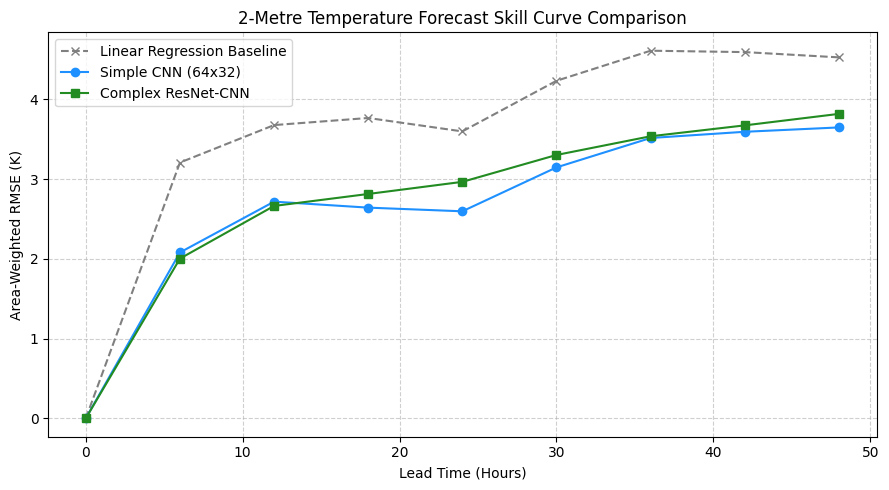

In [ ]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np

# Load verification netcdfs
eval_linear = xr.open_dataset("/content/eval_results_linear/deterministic.nc")
eval_simple = xr.open_dataset("/content/eval_results_simple/deterministic.nc")
eval_complex = xr.open_dataset("/content/eval_results_complex/deterministic.nc")

# Convert lead time coordinate to hours
lead_hours = eval_simple.lead_time.values.astype("timedelta64[h]").astype(int)

# Compute RMSE from MSE metric slices for 2m_temperature
rmse_linear = np.sqrt(eval_linear["2m_temperature"].sel(metric="mse").values)
rmse_simple = np.sqrt(eval_simple["2m_temperature"].sel(metric="mse").values)
rmse_complex = np.sqrt(eval_complex["2m_temperature"].sel(metric="mse").values)

# Plot the comparison
plt.figure(figsize=(9, 5))
plt.plot(lead_hours, rmse_linear, marker='x', linestyle='--', color='gray', label="Linear Regression Baseline")
plt.plot(lead_hours, rmse_simple, marker='o', color='dodgerblue', label="Simple CNN (64x32)")
plt.plot(lead_hours, rmse_complex, marker='s', color='forestgreen', label="Complex ResNet-CNN")

plt.xlabel("Lead Time (Hours)")
plt.ylabel("Area-Weighted RMSE (K)")
plt.title("2-Metre Temperature Forecast Skill Curve Comparison")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()